# Week 2 - Supervised Learning & Data Visualization

**Lab: Vehicle Data Analysis**

Trong 2 tuần thực hành này, chúng ta làm việc với bộ dữ liệu gồm ~846 xe (Vehicle Silhouettes):

| Tuần | Nội dung |
|:---:|:---|
| **Tuần 1** | EDA → Data Visualization → Classification (KNN) |
| **Tuần 2** | Regression (Linear/Ridge) → Hyperparameter Tuning → Full Pipeline |

**Dataset**: OpenML vehicle dataset — Vehicle Silhouettes

In [1]:
# ============================================================
# TUẦN 1 — EDA & CLASSIFICATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (
    accuracy_score, mean_squared_error, r2_score,
    classification_report, confusion_matrix
)
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

---

# PHẦN A — TẢI DỮ LIỆU VÀ KHÁM PHÁ (EDA)

## Bài 1: Tải dữ liệu

Chạy cell bên dưới để tải dataset vehicle từ OpenML. Đây là dữ liệu đã được chạy sẵn — hãy quan sát kết quả.

In [2]:
data = fetch_openml('vehicle', version=1, as_frame=True, parser='auto')


## Bài 2: Xem thông tin dataset

**Hãy trả lời bằng cách viết code trong cell bên dưới:**

**a)** Gõ `df.shape` để xem dataset có bao nhiêu dòng và bao nhiêu cột.

**b)** Gõ `df.columns` để liệt kê tên tất cả các cột.

**c)** Gõ `df.dtypes` để xem kiểu dữ liệu của mỗi cột. Cột nào là categorical, cột nào là numeric?

In [3]:
# Cell bài làm — viết code của bạn vào đây
df = data.frame
print(df.shape)
print(df.columns)
print(df.dtypes)

(846, 19)
Index(['COMPACTNESS', 'CIRCULARITY', 'DISTANCE_CIRCULARITY', 'RADIUS_RATIO',
       'PR.AXIS_ASPECT_RATIO', 'MAX.LENGTH_ASPECT_RATIO', 'SCATTER_RATIO',
       'ELONGATEDNESS', 'PR.AXIS_RECTANGULARITY', 'MAX.LENGTH_RECTANGULARITY',
       'SCALED_VARIANCE_MAJOR', 'SCALED_VARIANCE_MINOR',
       'SCALED_RADIUS_OF_GYRATION', 'SKEWNESS_ABOUT_MAJOR',
       'SKEWNESS_ABOUT_MINOR', 'KURTOSIS_ABOUT_MAJOR', 'KURTOSIS_ABOUT_MINOR',
       'HOLLOWS_RATIO', 'Class'],
      dtype='str')
COMPACTNESS                     int64
CIRCULARITY                     int64
DISTANCE_CIRCULARITY            int64
RADIUS_RATIO                    int64
PR.AXIS_ASPECT_RATIO            int64
MAX.LENGTH_ASPECT_RATIO         int64
SCATTER_RATIO                   int64
ELONGATEDNESS                   int64
PR.AXIS_RECTANGULARITY          int64
MAX.LENGTH_RECTANGULARITY       int64
SCALED_VARIANCE_MAJOR           int64
SCALED_VARIANCE_MINOR           int64
SCALED_RADIUS_OF_GYRATION       int64
SKEWNESS_ABOUT_M

## Bài 3: Kiểm tra giá trị missing (NaN)

**a)** Gõ `df.isnull().sum()` để đếm số giá trị NaN trong mỗi cột.

**b)** Có cột nào có nhiều giá trị NaN không? Nếu có, ta nên xử lý thế nào?

**c)** Xử lý: bỏ các dòng có NaN bằng `df = df.dropna()`.

Sau khi xử lý, gõ lại `df.shape` để xem số dòng còn lại.

In [4]:
# a) Đếm NaN mỗi cột
print(df.isnull().sum())
print("Tổng số NaN:", df.isnull().sum().sum())

# c) Bỏ các dòng có NaN
df = df.dropna()
print("Shape sau dropna:", df.shape)

COMPACTNESS                  0
CIRCULARITY                  0
DISTANCE_CIRCULARITY         0
RADIUS_RATIO                 0
PR.AXIS_ASPECT_RATIO         0
MAX.LENGTH_ASPECT_RATIO      0
SCATTER_RATIO                0
ELONGATEDNESS                0
PR.AXIS_RECTANGULARITY       0
MAX.LENGTH_RECTANGULARITY    0
SCALED_VARIANCE_MAJOR        0
SCALED_VARIANCE_MINOR        0
SCALED_RADIUS_OF_GYRATION    0
SKEWNESS_ABOUT_MAJOR         0
SKEWNESS_ABOUT_MINOR         0
KURTOSIS_ABOUT_MAJOR         0
KURTOSIS_ABOUT_MINOR         0
HOLLOWS_RATIO                0
Class                        0
dtype: int64
Tổng số NaN: 0
Shape sau dropna: (846, 19)


**Nhận xét Bài 3:** không cột nào có NaN, sau `dropna()` vẫn còn đủ **846 dòng × 19 cột**. Nếu một cột thiếu nhiều thì nên điền (median/KNN imputation) hoặc bỏ cả cột thay vì bỏ dòng, để không mất quá nhiều mẫu.

## Bài 4: Thống kê mô tả

**a)** Gõ `df.describe()` để hiển thị thống kê mô tả (mean, std, min, median, max) của các cột numeric.

**b)** Cột nào có range (max - min) lớn nhất?

**c)** Cột nào có giá trị mean lớn nhất? std lớn nhất?

In [5]:
desc = df.describe()
display(desc)

# b) Range lớn nhất; c) mean, std lớn nhất
rng = desc.loc['max'] - desc.loc['min']
print("Cột có range lớn nhất:", rng.idxmax(), "=", rng.max())
print("Cột có mean lớn nhất :", desc.loc['mean'].idxmax(), "=", round(desc.loc['mean'].max(), 2))
print("Cột có std lớn nhất  :", desc.loc['std'].idxmax(), "=", round(desc.loc['std'].max(), 2))

,COMPACTNESS,CIRCULARITY,DISTANCE_CIRCULARITY,RADIUS_RATIO,PR.AXIS_ASPECT_RATIO,MAX.LENGTH_ASPECT_RATIO,SCATTER_RATIO,ELONGATEDNESS,PR.AXIS_RECTANGULARITY,MAX.LENGTH_RECTANGULARITY,SCALED_VARIANCE_MAJOR,SCALED_VARIANCE_MINOR,SCALED_RADIUS_OF_GYRATION,SKEWNESS_ABOUT_MAJOR,SKEWNESS_ABOUT_MINOR,KURTOSIS_ABOUT_MAJOR,KURTOSIS_ABOUT_MINOR,HOLLOWS_RATIO
count,846.000000,846.000000,846.000000,846.000000,846.000000,846.000000,846.000000,846.000000,846.000000,846.000000,846.000000,846.000000,846.00000,846.000000,846.000000,846.000000,846.000000,846.000000
mean,93.678487,44.861702,82.088652,168.940898,61.693853,8.567376,168.839243,40.933806,20.582742,147.998818,188.625296,439.911348,174.70331,72.462175,6.377069,12.599291,188.932624,195.632388
std,8.234474,6.169866,15.771533,33.472183,7.888251,4.601217,33.244978,7.811560,2.592138,14.515652,31.394837,176.692614,32.54649,7.486974,4.918353,8.931240,6.163949,7.438797
min,73.000000,33.000000,40.000000,104.000000,47.000000,2.000000,112.000000,26.000000,17.000000,118.000000,130.000000,184.000000,109.00000,59.000000,0.000000,0.000000,176.000000,181.000000
25%,87.000000,40.000000,70.000000,141.000000,57.000000,7.000000,146.250000,33.000000,19.000000,137.000000,167.000000,318.250000,149.00000,67.000000,2.000000,5.000000,184.000000,190.250000
50%,93.000000,44.000000,80.000000,167.000000,61.000000,8.000000,157.000000,43.000000,20.000000,146.000000,178.500000,364.000000,173.00000,71.500000,6.000000,11.000000,188.000000,197.000000
75%,100.000000,49.000000,98.000000,195.000000,65.000000,10.000000,198.000000,46.000000,23.000000,159.000000,217.000000,587.000000,198.00000,75.000000,9.000000,19.000000,193.000000,201.000000
max,119.000000,59.000000,112.000000,333.000000,138.000000,55.000000,265.000000,61.000000,29.000000,188.000000,320.000000,1018.000000,268.00000,135.000000,22.000000,41.000000,206.000000,211.000000


Cột có range lớn nhất: SCALED_VARIANCE_MINOR = 834.0
Cột có mean lớn nhất : SCALED_VARIANCE_MINOR = 439.91
Cột có std lớn nhất  : SCALED_VARIANCE_MINOR = 176.69


**Nhận xét Bài 4:** `SCALED_VARIANCE_MINOR` có range lớn nhất (834), mean lớn nhất (≈ 440) và std lớn nhất (≈ 177), trong khi nhiều cột khác chỉ dao động vài chục đơn vị. Thang đo chênh lệch lớn như vậy nên **bắt buộc chuẩn hóa** trước KNN, nếu không khoảng cách sẽ bị cột này chi phối.

## Bài 5: Đếm giá trị của cột categorical

**a)** Tìm cột categorical (non-numeric). Dùng `df.select_dtypes(include='category').columns`.

**b)** Dùng `df['Class'].value_counts()` để đếm số xe trong mỗi nhóm (van, saab, bus, car).

**c)** Có bao nhiêu nhóm xe? Nhóm nào có nhiều xe nhất?

In [6]:
# Viết code vào đây
catcols = df.select_dtypes(include='category').columns
print(catcols)

print(df['Class'].value_counts())

print(df['Class'].nunique())
print(df['Class'].value_counts().idxmax())

Index(['Class'], dtype='str')
Class
bus     218
saab    217
opel    212
van     199
Name: count, dtype: int64
4
bus


**Nhận xét Bài 5:** cột categorical duy nhất là `Class`, gồm **4 nhóm xe**; nhiều nhất là `bus` (218), các nhóm khá cân bằng (199–218) nên accuracy là thước đo dùng được.

## Bài 6: Vẽ histogram — Cột numeric đầu tiên

**a)** Dùng `df.select_dtypes(include=np.number).columns` để liệt kê các cột numeric.

**b)** Chọn cột numeric đầu tiên và vẽ histogram bằng `plt.hist()`.

['COMPACTNESS', 'CIRCULARITY', 'DISTANCE_CIRCULARITY', 'RADIUS_RATIO', 'PR.AXIS_ASPECT_RATIO', 'MAX.LENGTH_ASPECT_RATIO', 'SCATTER_RATIO', 'ELONGATEDNESS', 'PR.AXIS_RECTANGULARITY', 'MAX.LENGTH_RECTANGULARITY', 'SCALED_VARIANCE_MAJOR', 'SCALED_VARIANCE_MINOR', 'SCALED_RADIUS_OF_GYRATION', 'SKEWNESS_ABOUT_MAJOR', 'SKEWNESS_ABOUT_MINOR', 'KURTOSIS_ABOUT_MAJOR', 'KURTOSIS_ABOUT_MINOR', 'HOLLOWS_RATIO']


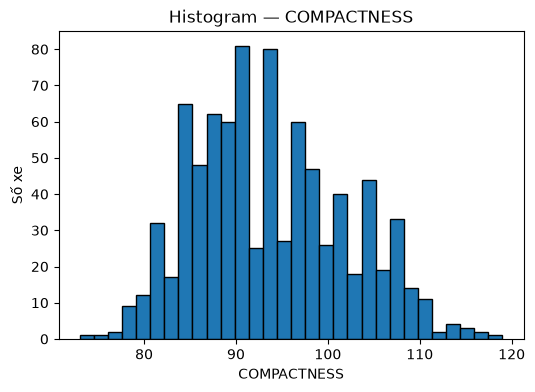

In [7]:
num_cols = df.select_dtypes(include=np.number).columns
print(list(num_cols))

col = num_cols[0]
plt.figure(figsize=(6, 4))
plt.hist(df[col], bins=30, edgecolor='black')
plt.title(f'Histogram — {col}')
plt.xlabel(col); plt.ylabel('Số xe')
plt.show()

## Bài 7: Vẽ histogram — 3 cột numeric cùng lúc

**Dùng `plt.subplots(1, 3, figsize=(15,4))` để vẽ 3 histogram cạnh nhau.**

Chọn 3 cột numeric bất kỳ và vẽ histogram cho mỗi cột.

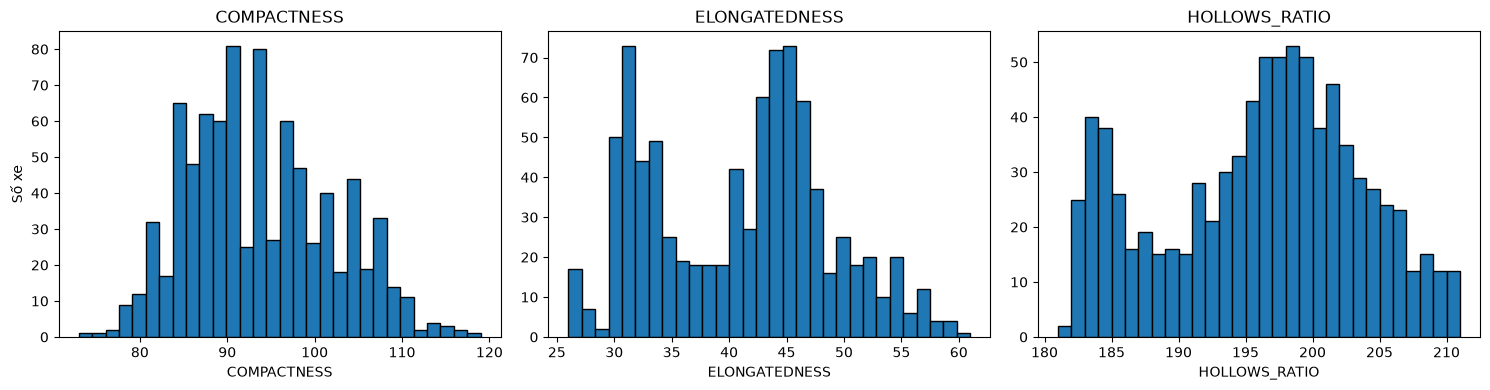

In [8]:
cols3 = ['COMPACTNESS', 'ELONGATEDNESS', 'HOLLOWS_RATIO']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, cols3):
    ax.hist(df[c], bins=30, edgecolor='black')
    ax.set_title(c); ax.set_xlabel(c)
axes[0].set_ylabel('Số xe')
plt.tight_layout(); plt.show()

## Bài 8: Vẽ Correlation Heatmap

Cặp thuộc tính nào có hệ số tương quan gần +1 nhất? Gần -1 nhất?

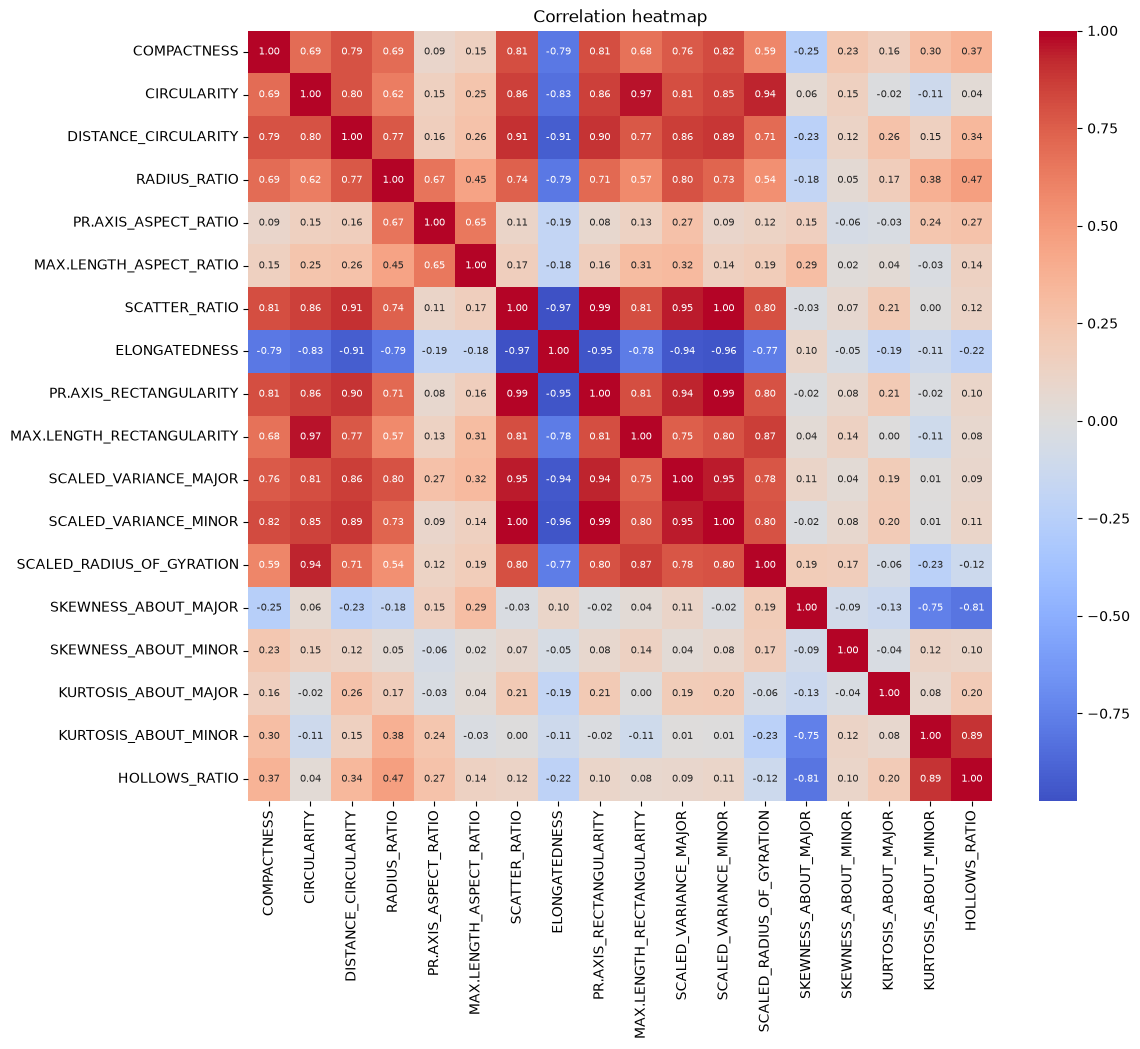

Gần +1 nhất: ('SCATTER_RATIO', 'SCALED_VARIANCE_MINOR') 0.996
Gần -1 nhất: ('SCATTER_RATIO', 'ELONGATEDNESS') -0.973


In [9]:
corr = df[num_cols].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Correlation heatmap')
plt.show()

# Tìm cặp gần +1 nhất và gần -1 nhất (bỏ đường chéo, mỗi cặp lấy 1 lần)
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("Gần +1 nhất:", pairs.idxmax(), round(pairs.max(), 3))
print("Gần -1 nhất:", pairs.idxmin(), round(pairs.min(), 3))

**Nhận xét Bài 8:**
- Gần +1 nhất: `SCATTER_RATIO` – `SCALED_VARIANCE_MINOR` (r = 0.996).
- Gần −1 nhất: `SCATTER_RATIO` – `ELONGATEDNESS` (r = −0.973).

Nhiều cặp feature gần như trùng thông tin (đa cộng tuyến mạnh). Điều này giải thích vì sao ở phần Regression, `SCALED_VARIANCE_MAJOR` được dự đoán rất chính xác từ các cột còn lại.

## Bài 9: Scatter Plot — 2 thuộc tính numeric

**a)** Chọn 2 cột numeric bất kỳ làm trục X và Y.

**b)** Vẽ scatter plot dùng `sns.scatterplot()`, tham số `hue='Class'` để tô màu theo nhóm xe.

**c)** Nhận xét: các nhóm xe phân bố khác nhau như thế nào trên đồ thị?

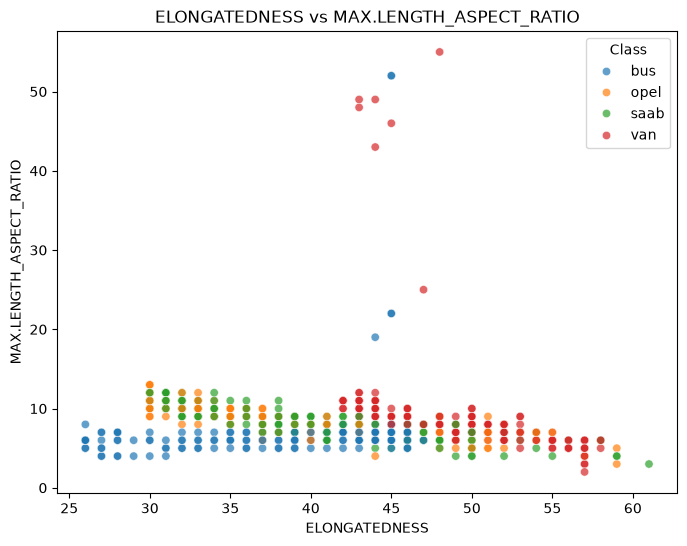

In [10]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='ELONGATEDNESS', y='MAX.LENGTH_ASPECT_RATIO', hue='Class', alpha=0.7)
plt.title('ELONGATEDNESS vs MAX.LENGTH_ASPECT_RATIO')
plt.show()

**Nhận xét Bài 9:**
- `bus` tách khá rõ: `MAX.LENGTH_ASPECT_RATIO` thấp nhất (≈ 4–8) ở mọi mức `ELONGATEDNESS`.
- `van` tập trung ở `ELONGATEDNESS` cao (≈ 42–58) và có vài điểm ngoại lai với tỉ lệ khung rất lớn (> 40).
- `opel` và `saab` **chồng lấn gần như hoàn toàn**: hai loại xe con có hình dáng tương tự, chỉ 2 feature này không đủ để phân biệt.

## Bài 10: Mã hóa cột categorical

**Mục tiêu:** Chuyển cột `Class` (text) thành số

In ra các lớp


In [11]:
le = LabelEncoder()
df['Class_enc'] = le.fit_transform(df['Class'])
print("Các lớp:", list(le.classes_))
print(dict(zip(le.classes_, le.transform(le.classes_))))

Các lớp: ['bus', 'opel', 'saab', 'van']
{'bus': np.int64(0), 'opel': np.int64(1), 'saab': np.int64(2), 'van': np.int64(3)}


## Bài 11: Tách X và y

**Mục tiêu:** Tách dữ liệu thành features (X) và target (y).

**c)** Chỉ giữ lại các cột numeric

**d)** In shape của X và y để kiểm tra.

In [12]:
X = df.drop(columns=['Class', 'Class_enc']).select_dtypes(include=np.number)
y = df['Class_enc']
print("X shape:", X.shape, "| y shape:", y.shape)

X shape: (846, 18) | y shape: (846,)


## Bài 12: Chia train/test

**Mục tiêu:** Chia dữ liệu thành tập huấn luyện (train) và tập kiểm tra (test).

**a)** Gán kết quả cho 4 biến: `X_train, X_test, y_train, y_test`.

**b)** In số mẫu của train và test.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", len(X_train), "mẫu | Test:", len(X_test), "mẫu")

Train: 676 mẫu | Test: 170 mẫu


## Bài 13: Chuẩn hóa dữ liệu (StandardScaler)

**Mục tiêu:** Đưa các features về cùng scale (mean=0, std=1) để KNN không bị thiên lệch.

**⚠️ Lưu ý quan trọng:** Luôn fit scaler trên **train**, rồi transform cả train VÀ test. Không bao giờ fit trên test!

**d)** Kiểm tra:  mean nên gần 0.

In [14]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit chỉ trên train
X_test_scaled = scaler.transform(X_test)

print("Mean train sau chuẩn hóa (5 cột đầu):", X_train_scaled.mean(axis=0)[:5].round(6))
print("Std  train sau chuẩn hóa (5 cột đầu):", X_train_scaled.std(axis=0)[:5].round(6))

Mean train sau chuẩn hóa (5 cột đầu): [-0. -0.  0.  0. -0.]
Std  train sau chuẩn hóa (5 cột đầu): [1. 1. 1. 1. 1.]


---

# PHẦN D — CLASSIFICATION (KNN)

## Bài 14: Train mô hình KNN lần đầu

**Mục tiêu:** Train KNN với k=5 và dự đoán trên tập test.


In [15]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)
print("10 dự đoán đầu:", le.inverse_transform(y_pred[:10]))

10 dự đoán đầu: ['bus' 'van' 'bus' 'opel' 'bus' 'van' 'van' 'saab' 'bus' 'saab']


## Bài 15: Đánh giá — Accuracy

**Mục tiêu:** Tính độ chính xác (accuracy) của mô hình.


In [16]:
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy KNN (k=5): {acc:.4f}")

Accuracy KNN (k=5): 0.7647


## Bài 16: Classification Report

**Mục tiêu:** Xem chi tiết precision, recall, F1-score cho từng nhóm xe.


In [17]:
print(classification_report(y_test, y_pred, target_names=le.classes_))

              precision    recall  f1-score   support

         bus       0.95      1.00      0.97        52
        opel       0.49      0.57      0.52        30
        saab       0.69      0.52      0.60        48
         van       0.82      0.90      0.86        40

    accuracy                           0.76       170
   macro avg       0.74      0.75      0.74       170
weighted avg       0.76      0.76      0.76       170



## Bài 17: Confusion Matrix

**Mục tiêu:** Vẽ confusion matrix để xem mô hình nhầm lẫn giữa các nhóm xe nào.


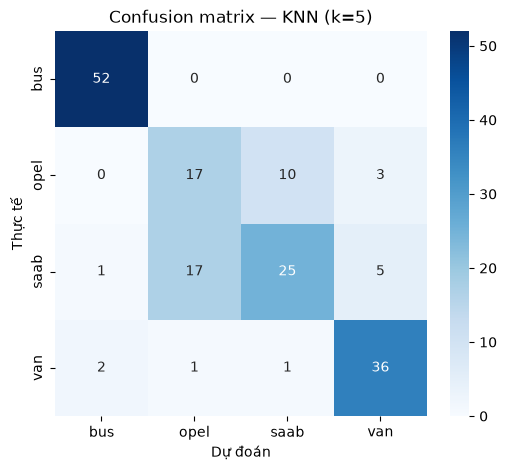

In [18]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Dự đoán'); plt.ylabel('Thực tế'); plt.title('Confusion matrix — KNN (k=5)')
plt.show()

**Nhận xét Bài 15–17:** accuracy KNN (k = 5) = **0.765**.
- `bus` gần như hoàn hảo (recall 1.00), `van` tốt (F1 0.86).
- Lỗi chủ yếu là **nhầm giữa `opel` và `saab`** (F1 chỉ 0.52 và 0.60), đúng như scatter plot ở Bài 9 đã cho thấy.

## Bài 18: Thử nghiệm nhiều giá trị k

**Mục tiêu:** Tìm giá trị k tốt nhất cho KNN.

**a)** Viết vòng for thử k = 1, 3, 5, 7, 9.

**b)** Vẽ đồ thị accuracy theo k (dùng `plt.plot()`).

**c)** Giá trị k nào cho accuracy cao nhất?

k=1: accuracy = 0.7118
k=3: accuracy = 0.7471
k=5: accuracy = 0.7647
k=7: accuracy = 0.7353
k=9: accuracy = 0.7294


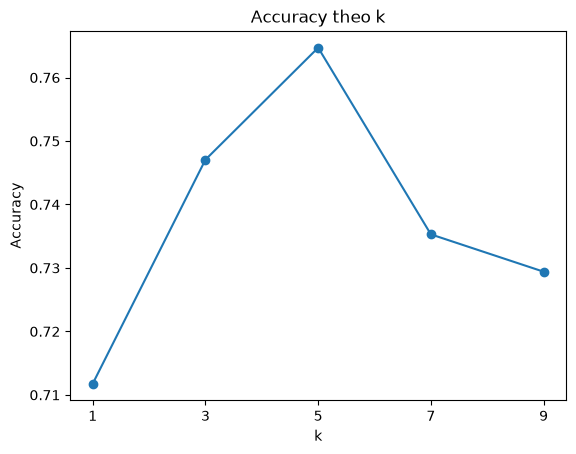

k tốt nhất: 5


In [19]:
ks = [1, 3, 5, 7, 9]
accs = []
for k in ks:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train_scaled, y_train)
    accs.append(accuracy_score(y_test, m.predict(X_test_scaled)))
    print(f"k={k}: accuracy = {accs[-1]:.4f}")

plt.plot(ks, accs, marker='o')
plt.xlabel('k'); plt.ylabel('Accuracy'); plt.title('Accuracy theo k')
plt.xticks(ks); plt.show()
print("k tốt nhất:", ks[int(np.argmax(accs))])

**Nhận xét Bài 18:** **k = 5** cho accuracy cao nhất (0.765). k = 1 dễ overfit theo nhiễu (0.712); k lớn hơn 5 làm ranh giới quá mượt, accuracy giảm dần.

---

# TUẦN 2 — REGRESSION & HYPERPARAMETER TUNING
.

---

# PHẦN E — REGRESSION

## Bài 19: Tách dữ liệu cho Regression

**Mục tiêu:** Tạo X_reg và y_reg mới cho bài toán regression.

**c)** Giữ cột numeric

**d)** Kiểm tra: `print(f"X_reg shape: {X_reg.shape}, y_reg shape: {y_reg.shape}")`.

In [20]:
target = 'SCALED_VARIANCE_MAJOR'
X_reg = df.drop(columns=[target, 'Class', 'Class_enc']).select_dtypes(include=np.number)
y_reg = df[target]
print(f"X_reg shape: {X_reg.shape}, y_reg shape: {y_reg.shape}")

X_reg shape: (846, 17), y_reg shape: (846,)


## Bài 20: Chia train/test và chuẩn hóa cho Regression

**Làm tương tự Bài 12 và Bài 13, nhưng với X_reg và y_reg.**


In [21]:
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

scaler_r = StandardScaler()
X_train_r_scaled = scaler_r.fit_transform(X_train_r)
X_test_r_scaled = scaler_r.transform(X_test_r)
print("Train:", X_train_r_scaled.shape, "| Test:", X_test_r_scaled.shape)

Train: (676, 17) | Test: (170, 17)


## Bài 21: Train Linear Regression

**Mục tiêu:** Train mô hình Linear Regression để dự đoán SCALED_VARIANCE_MAJOR.


In [22]:
lr = LinearRegression()
lr.fit(X_train_r_scaled, y_train_r)
y_pred_r = lr.predict(X_test_r_scaled)

coef = pd.Series(lr.coef_, index=X_reg.columns).sort_values(key=abs, ascending=False)
print("Intercept:", round(lr.intercept_, 3))
print("5 hệ số lớn nhất (theo trị tuyệt đối):")
print(coef.head().round(3))

Intercept: 188.175
5 hệ số lớn nhất (theo trị tuyệt đối):
SCALED_VARIANCE_MINOR    35.415
SCATTER_RATIO           -28.315
ELONGATEDNESS           -13.996
RADIUS_RATIO              9.989
SKEWNESS_ABOUT_MAJOR      9.027
dtype: float64


## Bài 22: Đánh giá Regression — MSE, RMSE, R²

**Mục tiêu:** Đánh giá chất lượng mô hình regression.


**d)** In cả 3 kết quả.

In [23]:
mse = mean_squared_error(y_test_r, y_pred_r)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_r, y_pred_r)
print(f"MSE  = {mse:.3f}")
print(f"RMSE = {rmse:.3f}")
print(f"R²   = {r2:.4f}")

MSE  = 20.568
RMSE = 4.535
R²   = 0.9812


## Bài 23: Vẽ Actual vs Predicted

**Mục tiêu:** Trực quan hóa kết quả regression.

**a)** Vẽ scatter plot: trục X = giá trị thực, trục Y = giá trị dự đoán.

**b)** Vẽ thêm đường chéo (đường perfect prediction).
.

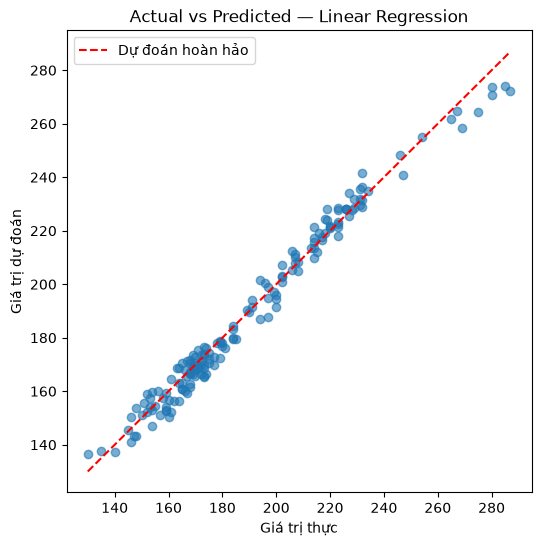

In [24]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test_r, y_pred_r, alpha=0.6)
lims = [min(y_test_r.min(), y_pred_r.min()), max(y_test_r.max(), y_pred_r.max())]
plt.plot(lims, lims, 'r--', label='Dự đoán hoàn hảo')
plt.xlabel('Giá trị thực'); plt.ylabel('Giá trị dự đoán')
plt.title('Actual vs Predicted — Linear Regression'); plt.legend()
plt.show()

**Nhận xét Bài 21–23:** Linear Regression đạt **R² = 0.981**, RMSE ≈ 4.5 (trên thang giá trị ~130–320). Các điểm nằm sát đường chéo. Kết quả tốt vì `SCALED_VARIANCE_MAJOR` tương quan rất mạnh với `SCATTER_RATIO`, `SCALED_VARIANCE_MINOR`… Hệ số lớn trái dấu nhau (+35 và −28) là dấu hiệu đa cộng tuyến: từng hệ số riêng lẻ không nên diễn giải trực tiếp.

## Bài 24: GridSearchCV cho KNN

**Mục tiêu:** Tự động tìm best parameters cho KNN thay vì thử từng k thủ công.

**a)** Định nghĩa parameter grid: `n_neighbors` = [3, 5, 7, 9], `weights` = ['uniform', 'distance'].

**b)** Tạo `GridSearchCV(KNeighborsClassifier(), param_grid, cv=5, scoring='accuracy')`.

**c)** Fit: `grid.fit(X_train_scaled, y_train)`.

**d)** In `grid.best_params_` và `grid.best_score_`.

In [25]:
param_grid = {'n_neighbors': [3, 5, 7, 9], 'weights': ['uniform', 'distance']}
grid = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5, scoring='accuracy')
grid.fit(X_train_scaled, y_train)

print("Best params:", grid.best_params_)
print(f"Best CV accuracy: {grid.best_score_:.4f}")
print(f"Accuracy trên test với best model: {accuracy_score(y_test, grid.predict(X_test_scaled)):.4f}")

Best params: {'n_neighbors': 5, 'weights': 'distance'}
Best CV accuracy: 0.7145
Accuracy trên test với best model: 0.7647


**Nhận xét Bài 24:** GridSearchCV chọn `n_neighbors = 5`, `weights = 'distance'`, CV accuracy 0.715. Accuracy trên test (0.765) cao hơn CV vì tập test chỉ có 170 mẫu, dao động nhiều; số CV đáng tin hơn để so sánh cấu hình.

## Bài 25: GridSearchCV cho Ridge Regression

**Mục tiêu:** Tìm best `alpha` cho Ridge Regression.


In [26]:
ridge_grid = GridSearchCV(Ridge(), {'alpha': np.logspace(-3, 3, 13)}, cv=5, scoring='r2')
ridge_grid.fit(X_train_r_scaled, y_train_r)
print("Best alpha:", ridge_grid.best_params_['alpha'])
print(f"Best CV R²: {ridge_grid.best_score_:.4f}")

Best alpha: 0.03162277660168379
Best CV R²: 0.9736


## Bài 26: So sánh Ridge trước và sau tuning

**Mục tiêu:** Xem hyperparameter tuning cải thiện R² bao nhiêu.


In [27]:
ridge_default = Ridge(alpha=1.0).fit(X_train_r_scaled, y_train_r)
ridge_best = ridge_grid.best_estimator_

r2_default = r2_score(y_test_r, ridge_default.predict(X_test_r_scaled))
r2_best = r2_score(y_test_r, ridge_best.predict(X_test_r_scaled))
print(f"Ridge alpha=1 (mặc định): R² test = {r2_default:.4f}")
print(f"Ridge alpha={ridge_grid.best_params_['alpha']:g} (tuned): R² test = {r2_best:.4f}")
print(f"Linear Regression        : R² test = {r2:.4f}")
print(f"Cải thiện do tuning: {r2_best - r2_default:+.4f}")

Ridge alpha=1 (mặc định): R² test = 0.9785
Ridge alpha=0.0316228 (tuned): R² test = 0.9809
Linear Regression        : R² test = 0.9812
Cải thiện do tuning: +0.0023


**Nhận xét Bài 25–26:** alpha tốt nhất rất nhỏ (≈ 0.03), tức là gần như không cần regularization; R² test tăng từ 0.9785 (alpha = 1) lên 0.9809, gần bằng Linear Regression (0.9812). Với 676 mẫu và 17 feature, mô hình tuyến tính không bị overfit nên Ridge cải thiện rất ít. Ridge hữu ích hơn khi số feature lớn so với số mẫu.

---

# PHẦN G — VIẾT LẠI FULL ML PIPELINE

## Bài 27: Full ML Pipeline — Classification (viết lại từ đầu)

**Mục tiêu:** Viết lại toàn bộ pipeline cho bài toán Classification, **từ bước 1 đến bước cuối**, không cần scaffold.

| Bước | Nội dung |
|:---:|:---|
| 1 | Tải lại dữ liệu: `fetch_openml('vehicle')` |
| 2 | Xử lý NaN: `df = df.dropna()` |
| 3 | Mã hóa `Class`: `LabelEncoder` → `Class_enc` |
| 4 | Tách `X` (features) và `y` (target = Class_enc) |
| 5 | Chia `train_test_split(X, y, test_size=0.2, random_state=42)` |
| 6 | `StandardScaler`: fit trên train, transform cả hai |
| 7 | Train `KNeighborsClassifier(n_neighbors=5)` |
| 8 | `accuracy_score(y_test, y_pred)` |
| 9 | `classification_report(y_test, y_pred)` |

In [28]:
# 1. Tải dữ liệu
df_c = fetch_openml('vehicle', version=1, as_frame=True, parser='auto').frame
# 2. Xử lý NaN
df_c = df_c.dropna()
# 3. Mã hóa Class
le_c = LabelEncoder()
df_c['Class_enc'] = le_c.fit_transform(df_c['Class'])
# 4. Tách X, y
Xc = df_c.drop(columns=['Class', 'Class_enc'])
yc = df_c['Class_enc']
# 5. Chia train/test
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.2, random_state=42)
# 6. StandardScaler
sc_c = StandardScaler().fit(Xc_tr)
Xc_tr, Xc_te = sc_c.transform(Xc_tr), sc_c.transform(Xc_te)
# 7. KNN
knn_c = KNeighborsClassifier(n_neighbors=5).fit(Xc_tr, yc_tr)
yc_pred = knn_c.predict(Xc_te)
# 8. Accuracy
print(f"Accuracy: {accuracy_score(yc_te, yc_pred):.4f}")
# 9. Classification report
print(classification_report(yc_te, yc_pred, target_names=le_c.classes_))

Accuracy: 0.7647
              precision    recall  f1-score   support

         bus       0.95      1.00      0.97        52
        opel       0.49      0.57      0.52        30
        saab       0.69      0.52      0.60        48
         van       0.82      0.90      0.86        40

    accuracy                           0.76       170
   macro avg       0.74      0.75      0.74       170
weighted avg       0.76      0.76      0.76       170



## Bài 28: Full ML Pipeline — Regression (viết lại từ đầu)

Tương tự Bài 27, nhưng cho bài toán **Regression** (dự đoán `SCALED_VARIANCE_MAJOR`).

| Bước | Nội dung |
|:---:|:---|
| 1 | Tải dữ liệu |
| 2 | Xử lý NaN |
| 3 | Tách `X_reg` (bỏ `SCALED_VARIANCE_MAJOR`, categorical) và `y_reg` (= `SCALED_VARIANCE_MAJOR`) |
| 4 | `train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)` |
| 5 | `StandardScaler` |
| 6 | Train `LinearRegression()` |
| 7 | `mean_squared_error`, `r2_score` |
| 8 | Vẽ Actual vs Predicted scatter plot |

MSE = 20.568 | R² = 0.9812


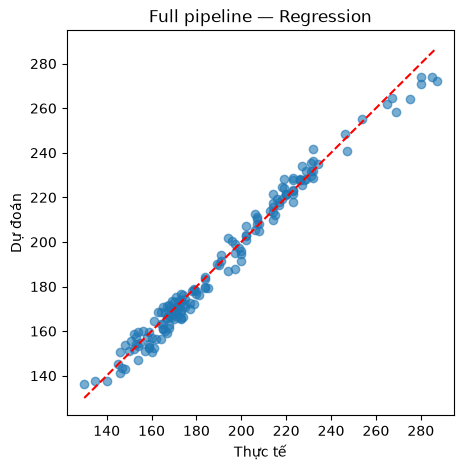

In [29]:
# 1-2. Tải dữ liệu, xử lý NaN
df_r = fetch_openml('vehicle', version=1, as_frame=True, parser='auto').frame.dropna()
# 3. Tách X_reg, y_reg
Xr = df_r.drop(columns=['SCALED_VARIANCE_MAJOR', 'Class'])
yr = df_r['SCALED_VARIANCE_MAJOR']
# 4. Chia train/test
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=42)
# 5. StandardScaler
sc_r = StandardScaler().fit(Xr_tr)
Xr_tr, Xr_te = sc_r.transform(Xr_tr), sc_r.transform(Xr_te)
# 6. Linear Regression
yr_pred = LinearRegression().fit(Xr_tr, yr_tr).predict(Xr_te)
# 7. MSE, R²
print(f"MSE = {mean_squared_error(yr_te, yr_pred):.3f} | R² = {r2_score(yr_te, yr_pred):.4f}")
# 8. Actual vs Predicted
plt.figure(figsize=(5, 5))
plt.scatter(yr_te, yr_pred, alpha=0.6)
plt.plot([yr_te.min(), yr_te.max()], [yr_te.min(), yr_te.max()], 'r--')
plt.xlabel('Thực tế'); plt.ylabel('Dự đoán'); plt.title('Full pipeline — Regression')
plt.show()

---

## Bài tập về nhà (Homework)

**1.** Thử thuật toán **khác** cho Classification:
   - `RandomForestClassifier` (n_estimators=100)
   - `SVC` (Support Vector Machine)
   So sánh accuracy với KNN.

**2.** Vẽ **learning curve** để phát hiện overfitting/underfitting:
   `sklearn.model_selection.learning_curve(KNeighborsClassifier(), X_train_scaled, y_train, cv=5)`

**3.** Thay đổi tỉ lệ **train/test**: thử 70/30, 90/10. Quan sát accuracy và R² thay đổi thế nào.

**4.** Áp dụng pipeline lên dataset khác:
   `fetch_openml('wine-quality-white', version=3)`
   - Classification: dự đoán `quality` (≤5 = thấp, >5 = cao)
   - Regression: dự đoán trực tiếp giá trị `quality`

### Homework 1: RandomForest và SVC so với KNN

In [30]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

models = {
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'RandomForest (100 cây)': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVC (RBF)': SVC(random_state=42),
}
for name, m in models.items():
    m.fit(X_train_scaled, y_train)
    print(f"{name:25s} accuracy = {accuracy_score(y_test, m.predict(X_test_scaled)):.4f}")

KNN (k=5)                 accuracy = 0.7647


RandomForest (100 cây)    accuracy = 0.7706
SVC (RBF)                 accuracy = 0.7471


**Nhận xét HW1:** Random Forest nhỉnh nhất (0.771), KNN 0.765, SVC 0.747 (tham số mặc định). Chênh lệch nhỏ trên 170 mẫu test; cả 3 mô hình đều vướng cùng một chỗ là phân biệt `opel`/`saab`.

### Homework 2: Learning curve của KNN

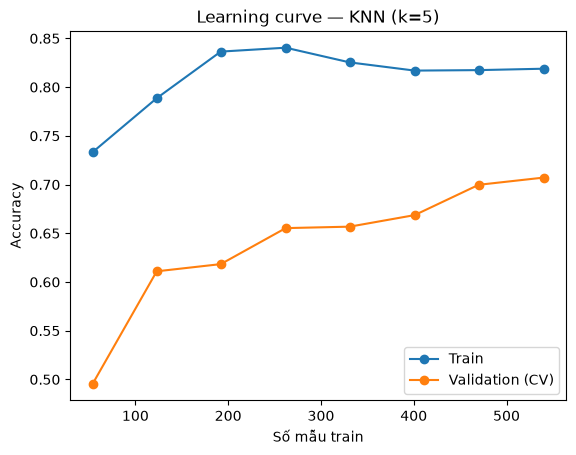

Khoảng cách train − validation ở cuối: 0.1117


In [31]:
from sklearn.model_selection import learning_curve

sizes, train_sc, val_sc = learning_curve(KNeighborsClassifier(), X_train_scaled, y_train, cv=5,
                                         train_sizes=np.linspace(0.1, 1.0, 8))
plt.plot(sizes, train_sc.mean(axis=1), 'o-', label='Train')
plt.plot(sizes, val_sc.mean(axis=1), 'o-', label='Validation (CV)')
plt.xlabel('Số mẫu train'); plt.ylabel('Accuracy'); plt.title('Learning curve — KNN (k=5)')
plt.legend(); plt.show()
print("Khoảng cách train − validation ở cuối:", round(train_sc.mean(axis=1)[-1] - val_sc.mean(axis=1)[-1], 4))

**Nhận xét HW2:** accuracy train ổn định quanh 0.82 trong khi validation tăng dần từ 0.50 lên 0.71 và **chưa bão hòa**, khoảng cách còn ~0.11. Mô hình hơi overfit (variance cao); thêm dữ liệu sẽ còn giúp tăng accuracy.

### Homework 3: Thay đổi tỉ lệ train/test

In [32]:
rows = []
for test_size in [0.3, 0.2, 0.1]:
    # Classification
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=test_size, random_state=42)
    s = StandardScaler().fit(Xa)
    acc_ = accuracy_score(yb, KNeighborsClassifier(5).fit(s.transform(Xa), ya).predict(s.transform(Xb)))
    # Regression
    Xa, Xb, ya, yb = train_test_split(X_reg, y_reg, test_size=test_size, random_state=42)
    s = StandardScaler().fit(Xa)
    r2_ = r2_score(yb, LinearRegression().fit(s.transform(Xa), ya).predict(s.transform(Xb)))
    rows.append({'train/test': f"{int((1 - test_size) * 100)}/{int(test_size * 100)}",
                 'KNN accuracy': round(acc_, 4), 'Linear R²': round(r2_, 4)})
display(pd.DataFrame(rows))

,train/test,KNN accuracy,Linear R²
0,70/30,0.7677,0.9795
1,80/20,0.7647,0.9812
2,90/10,0.7765,0.9788


**Nhận xét HW3:** accuracy (0.765–0.777) và R² (0.979–0.981) thay đổi rất ít giữa các tỉ lệ. Tập test càng nhỏ (90/10 chỉ còn 85 mẫu) thì con số càng dao động, nên khác biệt ở đây chủ yếu là nhiễu chứ không phải do lượng dữ liệu train.

### Homework 4: Áp dụng pipeline lên `wine-quality-white`

In [33]:
try:
    wine = fetch_openml('wine-quality-white', version=3, as_frame=True, parser='auto')
except Exception:
    wine = fetch_openml('wine-quality-white', as_frame=True, parser='auto')
dfw = wine.frame.dropna()
tcol = wine.target_names[0]
quality = pd.to_numeric(dfw[tcol])
if quality.min() == 1:      # bản trên OpenML mã hóa lại 3..9 thành 1..7 -> đưa về thang gốc
    quality = quality + 2
Xw = dfw.drop(columns=[tcol]).select_dtypes(include=np.number)
print("Shape:", Xw.shape, "| phân bố quality:", quality.value_counts().sort_index().to_dict())

# Classification: quality <= 5 -> thấp (0), > 5 -> cao (1)
yw = (quality > 5).astype(int)
Xa, Xb, ya, yb = train_test_split(Xw, yw, test_size=0.2, random_state=42, stratify=yw)
s = StandardScaler().fit(Xa)
pred = KNeighborsClassifier(5).fit(s.transform(Xa), ya).predict(s.transform(Xb))
print(f"Classification (KNN, k=5) accuracy = {accuracy_score(yb, pred):.4f}")

# Regression: dự đoán trực tiếp quality
Xa, Xb, ya, yb = train_test_split(Xw, quality, test_size=0.2, random_state=42)
s = StandardScaler().fit(Xa)
pred = LinearRegression().fit(s.transform(Xa), ya).predict(s.transform(Xb))
print(f"Regression (Linear) RMSE = {np.sqrt(mean_squared_error(yb, pred)):.4f} | R² = {r2_score(yb, pred):.4f}")

Shape: (4898, 11) | phân bố quality: {3: 20, 4: 163, 5: 1457, 6: 2198, 7: 880, 8: 175, 9: 5}
Classification (KNN, k=5) accuracy = 0.7571
Regression (Linear) RMSE = 0.7543 | R² = 0.2653


**Nhận xét HW4:** bản trên OpenML mã hóa lại `quality` từ 3–9 thành 1–7, nên phải cộng 2 để dùng đúng ngưỡng "≤ 5 là thấp" của đề.
- Classification (thấp / cao): KNN accuracy **0.757**.
- Regression trực tiếp `quality`: R² chỉ **0.265**, RMSE ≈ 0.75 điểm. Chất lượng rượu khó dự đoán bằng mô hình tuyến tính từ các chỉ số hóa học; quan hệ phi tuyến và phân bố dồn ở mức 5–6 khiến bài toán khó hơn nhiều so với dữ liệu vehicle.